1.  Gunakan arsitektur VGG untuk melatih data nya.

MODEL VGG16 - TRANSFER LEARNING

In [1]:
pip install wget

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=056c01b5099c485451d3bff5ece8fb7c2c42c314480d3c1425fe2756bc965e7e
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


In [2]:
from pathlib import Path
import os
os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")
import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow :", tf.__version__)
print("GPU :", gpus if gpus else "Tidak terdeteksi ; pelatihan menggunakan CPU.")
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"
print("Folder gambar :", image_dir)

Folder gambar : data/dataset/Images


In [4]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"
print("Folder gambar :", image_dir)

# Memuat data gambar untuk mendefinisikan nama_kelas, X, dan y
nama_kelas = sorted([d.name for d in image_dir.iterdir() if d.is_dir()])
X = []
y = []

for label_idx, kelas in enumerate(nama_kelas):
    kelas_dir = image_dir / kelas
    for img_path in kelas_dir.glob("*.tif"):
        img = Image.open(img_path).resize(IMG_SIZE)
        X.append(np.array(img))
        y.append(label_idx)

X = np.array(X)
y = np.array(y)

# Memastikan kelengkapan dataset sesuai dengan assert
assert len(nama_kelas) == 21 and len(X) == 2100, \
" Periksa kelengkapan dataset "
assert np.all(np.bincount(y) == 100), \
" Setiap kelas seharusnya memiliki 100 gambar "
print(" Bentuk data :", X.shape)
print(" Kelas :", nama_kelas)

Folder gambar : data/dataset/Images
 Bentuk data : (2100, 224, 224, 3)
 Kelas : ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


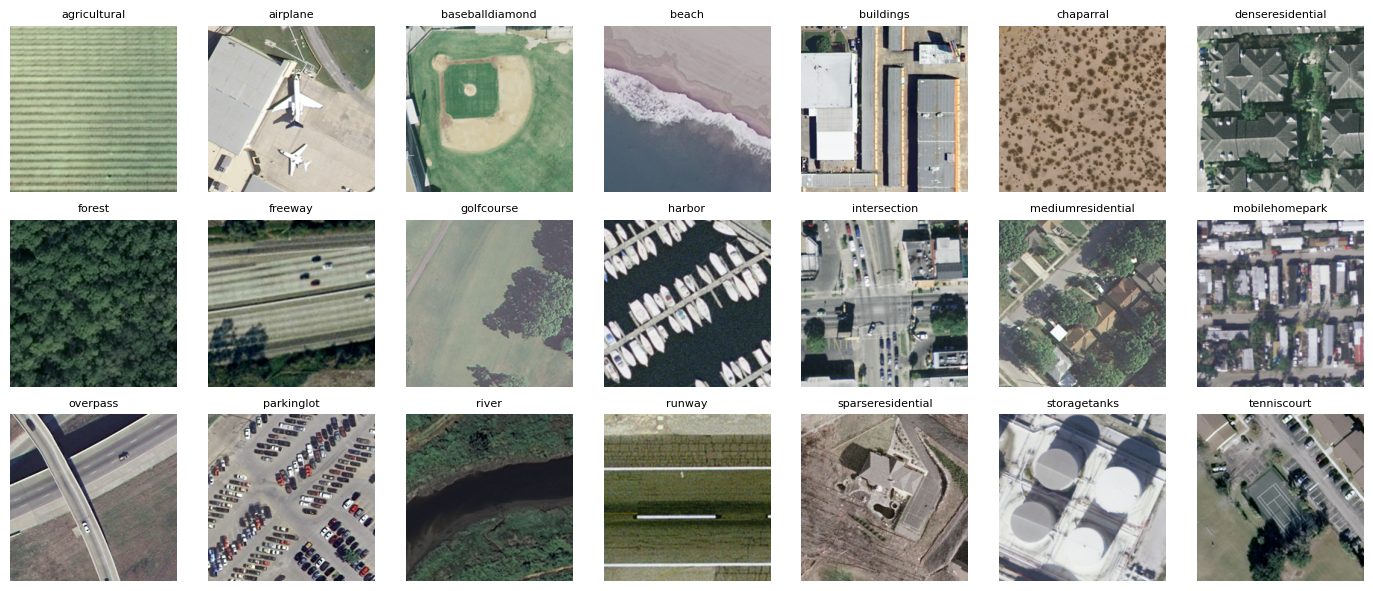

In [5]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))
for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
x_train , x_sisa , y_train , y_sisa = train_test_split (
X ,
y ,
test_size =0.30 ,
stratify =y ,
random_state =42
)
x_val , x_test , y_val , y_test = train_test_split (
x_sisa ,
y_sisa ,
test_size =0.50 ,
stratify = y_sisa ,
random_state =42
)
print (
" Train :",
len ( y_train ) ,
" Validation :",
len ( y_val ) ,
" Test :",
len ( y_test )
)

 Train : 1470  Validation : 315  Test : 315


In [7]:
# ============================================================
# BAGIAN 1: PEMBUATAN MODEL VGG16 (TRANSFER LEARNING)
# ============================================================

# Pastikan ukuran input sudah terdefinisi
IMG_SIZE = (224, 224)
NUM_CLASSES = len(nama_kelas)

print("Ukuran gambar:", IMG_SIZE)
print("Jumlah kelas:", NUM_CLASSES)

# Memuat VGG16 pretrained ImageNet tanpa classifier bawaan
base_model = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Membekukan bobot backbone VGG16
base_model.trainable = False

# Membuat input model
inputs = tf.keras.Input(shape=(224, 224, 3))

# Preprocessing khusus VGG16
x = tf.keras.applications.vgg16.preprocess_input(inputs)

# Ekstraksi fitur dengan VGG16
x = base_model(x, training=False)

# Lapisan klasifikasi untuk 21 kelas UC Merced
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Model akhir
model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="vgg16_ucmerced"
)

# Kompilasi model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Backbone VGG16 dibekukan:", not base_model.trainable)


Ukuran gambar: (224, 224)
Jumlah kelas: 21
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 21)        │     10,773 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,725,461 (56.17 MB)

 Trainable params: 10,773 (42.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Backbone VGG16 dibekukan: True


In [8]:
# ============================================================
# BAGIAN 2: TRAINING MODEL VGG16
# =============================================================
import tensorflow as tf

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=2
)

print("Epoch dijalankan:", len(history.history["loss"]))


Epoch 1/10
92/92 - 19s - 210ms/step - accuracy: 0.2143 - loss: 5.5612 - val_accuracy: 0.5619 - val_loss: 1.7889 - learning_rate: 0.0010
Epoch 2/10
92/92 - 7s - 75ms/step - accuracy: 0.5748 - loss: 1.9532 - val_accuracy: 0.7587 - val_loss: 0.8919 - learning_rate: 0.0010
Epoch 3/10
92/92 - 7s - 75ms/step - accuracy: 0.7102 - loss: 1.1710 - val_accuracy: 0.8317 - val_loss: 0.5888 - learning_rate: 0.0010
Epoch 4/10
92/92 - 7s - 75ms/step - accuracy: 0.7912 - loss: 0.7983 - val_accuracy: 0.8413 - val_loss: 0.4731 - learning_rate: 0.0010
Epoch 5/10
92/92 - 7s - 76ms/step - accuracy: 0.8333 - loss: 0.5877 - val_accuracy: 0.8825 - val_loss: 0.3802 - learning_rate: 0.0010
Epoch 6/10
92/92 - 7s - 78ms/step - accuracy: 0.8707 - loss: 0.4498 - val_accuracy: 0.8794 - val_loss: 0.3326 - learning_rate: 0.0010
Epoch 7/10
92/92 - 7s - 79ms/step - accuracy: 0.8939 - loss: 0.3454 - val_accuracy: 0.9048 - val_loss: 0.2934 - learning_rate: 0.0010
Epoch 8/10
92/92 - 7s - 81ms/step - accuracy: 0.9061 - loss:

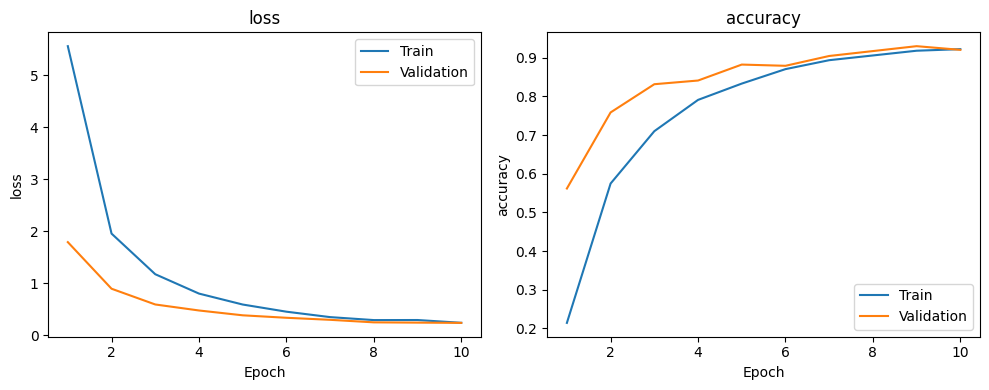

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 0.3183 | Test accuracy : 92.06%
                   precision    recall  f1-score   support

     agricultural       1.00      0.93      0.97        15
         airplane       1.00      1.00      1.00        15
  baseballdiamond       0.93      0.93      0.93        15
            beach       1.00      1.00      1.00        15
        buildings       0.89      0.53      0.67        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.79      0.73      0.76        15
           forest       0.94      1.00      0.97        15
          freeway       1.00      1.00      1.00        15
       golfcourse       1.00      0.87      0.93        15
           harbor       1.00      1.00      1.00        15
     intersection       0.87      0.87      0.87        15
mediumresidential       0.76      0.87      0.81        15
   mobilehomepark       0.88      1.00      0.94        15
         overpass       1.00      0.93      0.97        15
       park

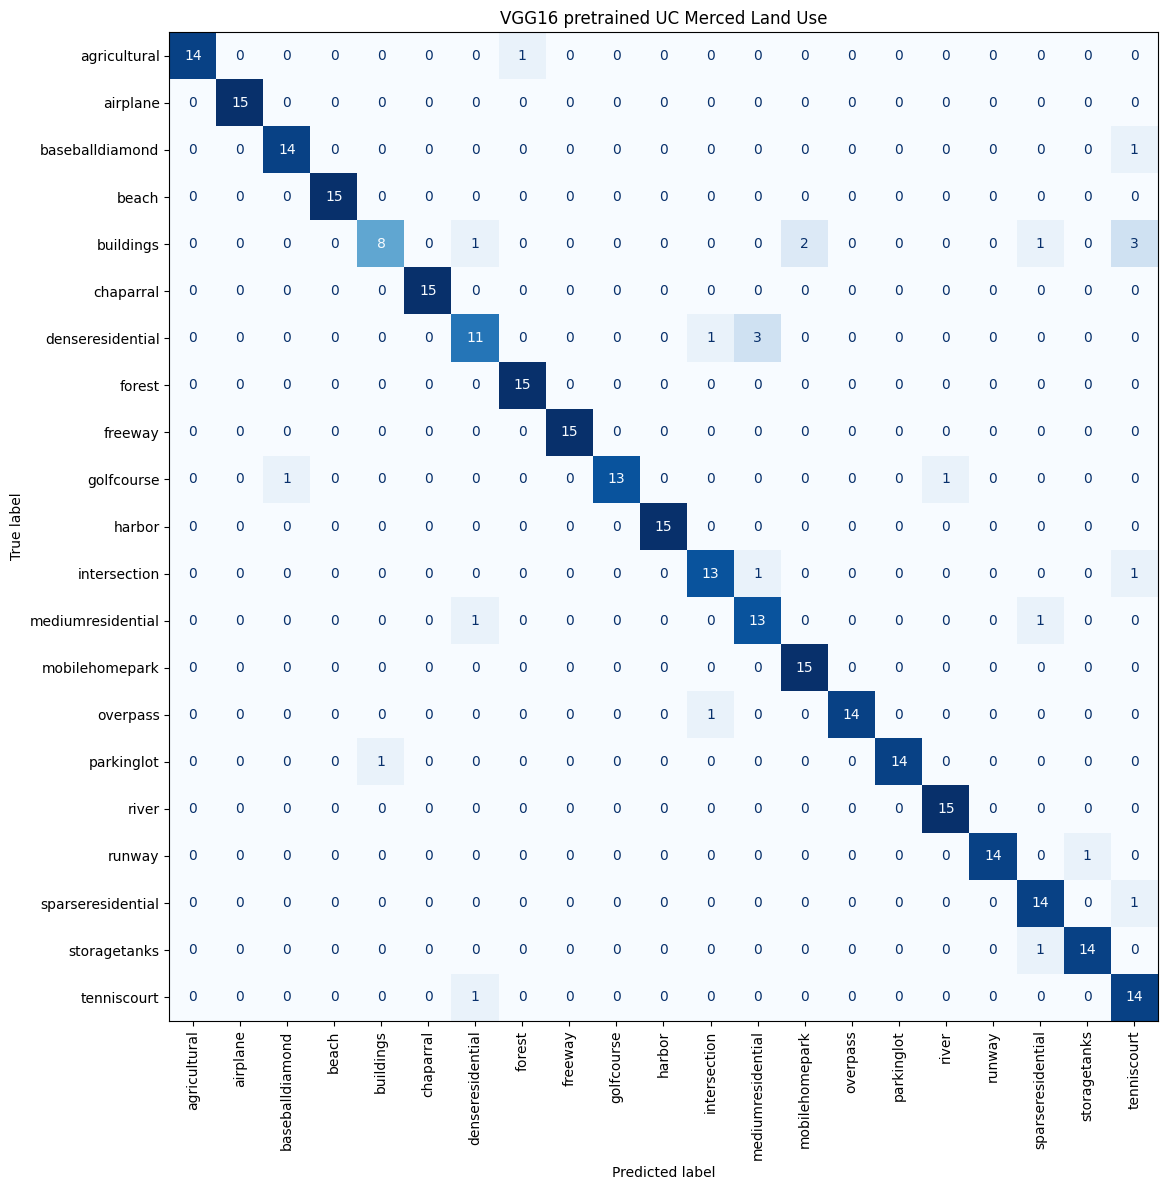

In [10]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test, batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("VGG16 pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

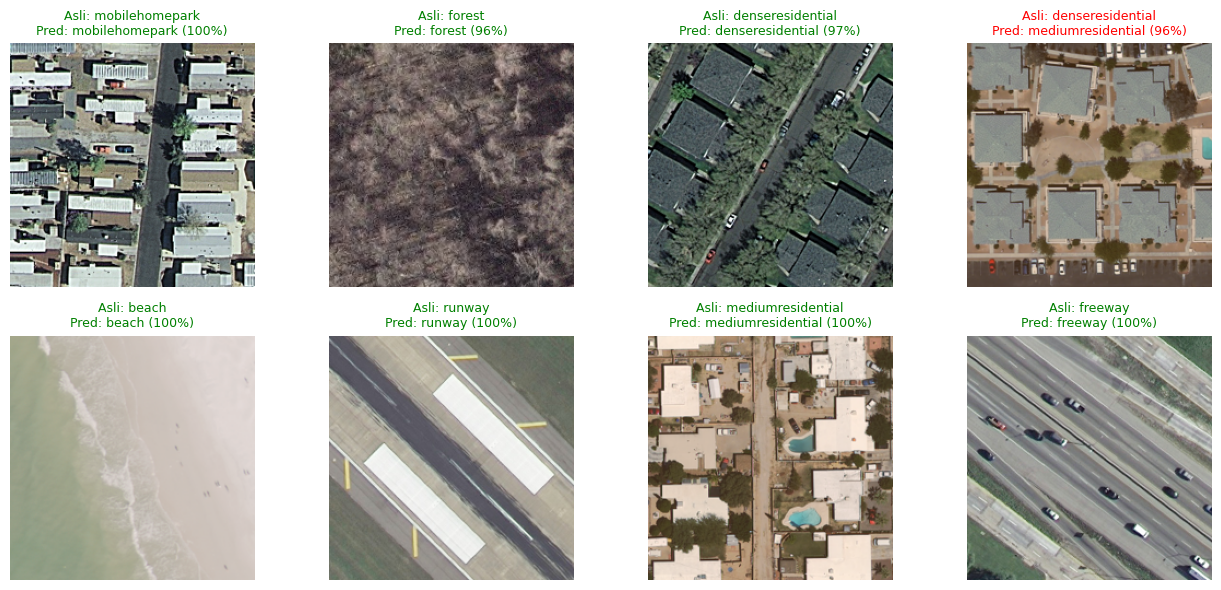

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

2. Gunakan arsitektur lain (AlexNet, MobileNet, dsb) untuk melatih data nya.

A. MODEL ALEXNET

In [12]:
import os
import zipfile
import urllib.request
import random
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Semua library berhasil di-import!")
print("Versi PyTorch:", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Perangkat yang digunakan:", device)

Semua library berhasil di-import!
Versi PyTorch: 2.11.0+cu130
Perangkat yang digunakan: cuda


In [13]:
dataset_url = (
    "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/"
    "UCMerced_LandUse.zip"
)

zip_path = "/content/UCMerced_LandUse.zip"
extract_path = "/content/UCMerced_LandUse"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(dataset_url, zip_path)
    print("Dataset berhasil diunduh.")
else:
    print("File dataset sudah tersedia.")

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("Dataset berhasil diekstrak.")

image_folder = None

for root, dirs, files in os.walk(extract_path):
    if os.path.basename(root).lower() == "images":
        image_folder = root
        break

if image_folder is None:
    raise FileNotFoundError(
        "Folder Images tidak ditemukan. Periksa struktur dataset."
    )

print("Lokasi dataset:", image_folder)

class_names = sorted([
    folder for folder in os.listdir(image_folder)
    if os.path.isdir(os.path.join(image_folder, folder))
])

print("Jumlah kelas:", len(class_names))
print("Nama kelas:", class_names)

assert len(class_names) == 21, "Dataset seharusnya memiliki 21 kelas."

Dataset berhasil diunduh.
Dataset berhasil diekstrak.
Lokasi dataset: /content/UCMerced_LandUse/dataset/Images
Jumlah kelas: 21
Nama kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


In [14]:
image_size = 224
batch_size = 32

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = datasets.ImageFolder(
    root=image_folder,
    transform=transform
)

print("Jumlah seluruh gambar:", len(dataset))
print("Jumlah kelas:", len(dataset.classes))
print("Contoh nama kelas:", dataset.classes[:5])

Jumlah seluruh gambar: 2100
Jumlah kelas: 21
Contoh nama kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings']


In [17]:
indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

# 70% training, 30% sisanya
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# 15% validation dan 15% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_idx]
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=2
)

print("Jumlah data training:", len(train_dataset))
print("Jumlah data validation:", len(val_dataset))
print("Jumlah data testing:", len(test_dataset))

Jumlah data training: 1470
Jumlah data validation: 315
Jumlah data testing: 315


In [16]:
weights = models.AlexNet_Weights.DEFAULT
model = models.alexnet(weights=weights)

# Membekukan convolutional layers pretrained
for param in model.features.parameters():
    param.requires_grad = False

# Mengganti layer output menjadi 21 kelas
in_features = model.classifier[6].in_features
model.classifier[6] = nn.Linear(in_features, 21)

# Memindahkan model ke GPU atau CPU
model = model.to(device)

print(model)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 93.8MB/s]


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [18]:
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

# Convolutional layer 1
x = tf.keras.layers.Conv2D(
    96, kernel_size=11, strides=4,
    activation="relu", padding="valid"
)(inputs)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Convolutional layer 2
x = tf.keras.layers.Conv2D(
    256, kernel_size=5,
    activation="relu", padding="same"
)(x)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Convolutional layers 3, 4, and 5
x = tf.keras.layers.Conv2D(
    384, kernel_size=3,
    activation="relu", padding="same"
)(x)

x = tf.keras.layers.Conv2D(
    384, kernel_size=3,
    activation="relu", padding="same"
)(x)

x = tf.keras.layers.Conv2D(
    256, kernel_size=3,
    activation="relu", padding="same"
)(x)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Flatten and fully connected layers
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    4096, activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.5)(x)

x = tf.keras.layers.Dense(
    4096, activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.5)(x)

# Output layer
outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

# Build model
model = tf.keras.Model(
    inputs,
    outputs,
    name="alexnet_ucmerced"
)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "alexnet_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 21)             │        86,037 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,833,045 (178.65 MB)

 Trainable params: 46,833,045 (178.65 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 25s - 273ms/step - accuracy: 0.0408 - loss: 6.6899 - val_accuracy: 0.0476 - val_loss: 3.0448
Epoch 2/10
92/92 - 3s - 30ms/step - accuracy: 0.0367 - loss: 3.1737 - val_accuracy: 0.0508 - val_loss: 3.0445
Epoch 3/10
92/92 - 3s - 28ms/step - accuracy: 0.0340 - loss: 3.0489 - val_accuracy: 0.0476 - val_loss: 3.0448
Epoch 4/10
92/92 - 3s - 28ms/step - accuracy: 0.0374 - loss: 3.0468 - val_accuracy: 0.0476 - val_loss: 3.0454
Epoch 5/10
92/92 - 3s - 28ms/step - accuracy: 0.0374 - loss: 3.0472 - val_accuracy: 0.0476 - val_loss: 3.0455
Epoch dijalankan : 5


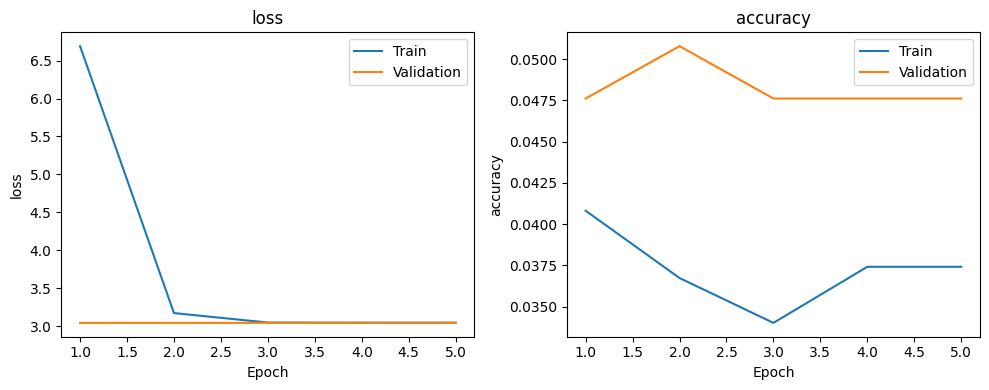

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 3.0450 | Test accuracy : 4.76%
                   precision    recall  f1-score   support

     agricultural       0.00      0.00      0.00        15
         airplane       0.00      0.00      0.00        15
  baseballdiamond       0.00      0.00      0.00        15
            beach       0.00      0.00      0.00        15
        buildings       0.00      0.00      0.00        15
        chaparral       0.00      0.00      0.00        15
 denseresidential       0.00      0.00      0.00        15
           forest       0.00      0.00      0.00        15
          freeway       0.00      0.00      0.00        15
       golfcourse       0.00      0.00      0.00        15
           harbor       0.00      0.00      0.00        15
     intersection       0.00      0.00      0.00        15
mediumresidential       0.00      0.00      0.00        15
   mobilehomepark       0.05      1.00      0.09        15
         overpass       0.00      0.00      0.00        15
       parki

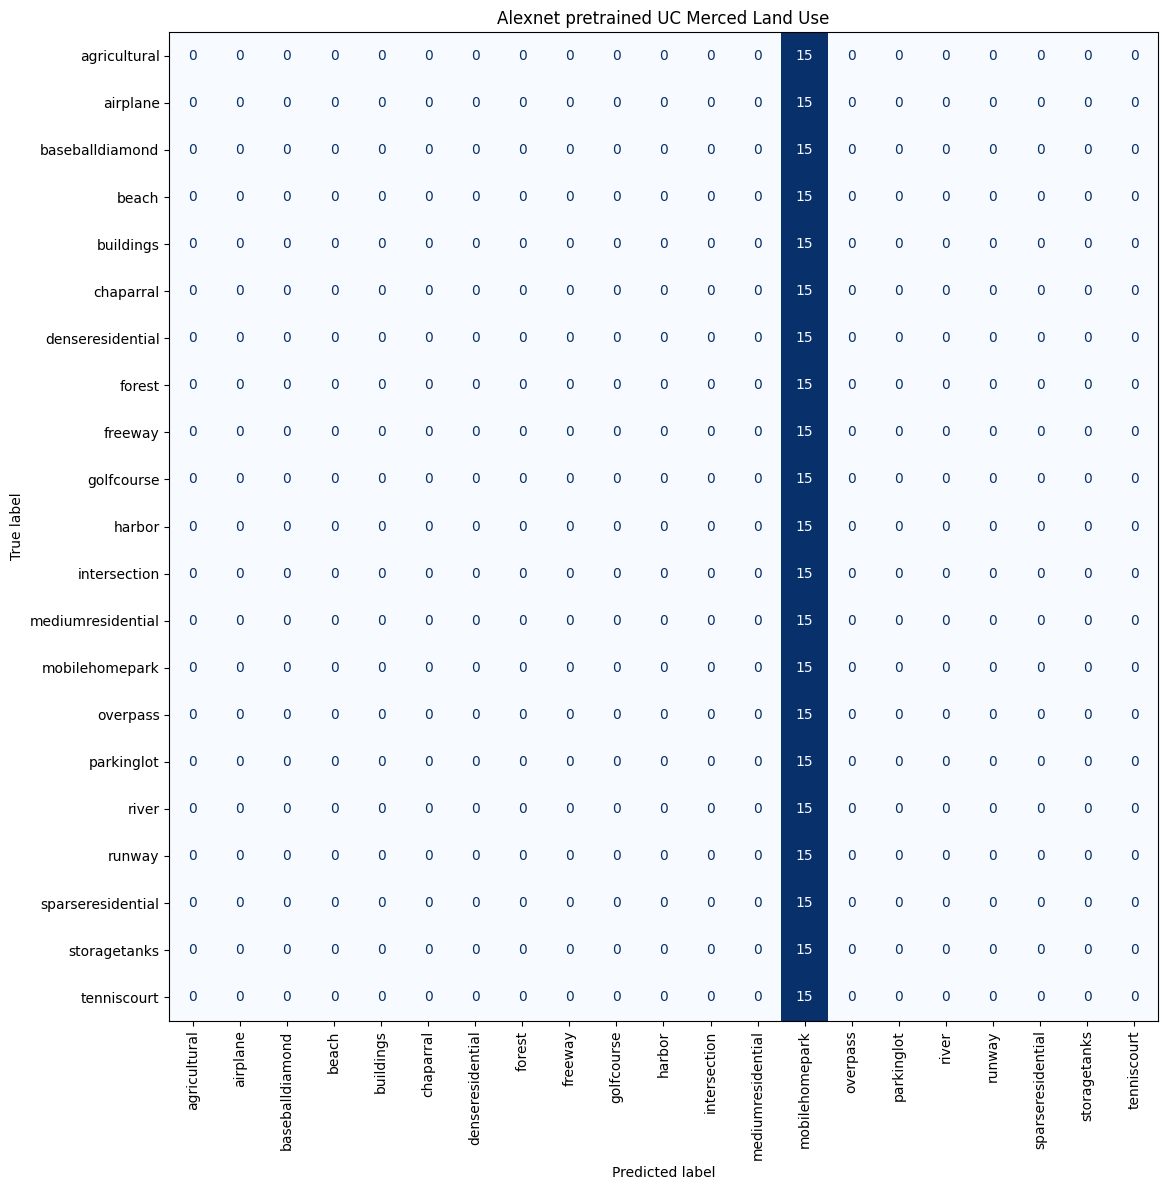

In [21]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("Alexnet pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

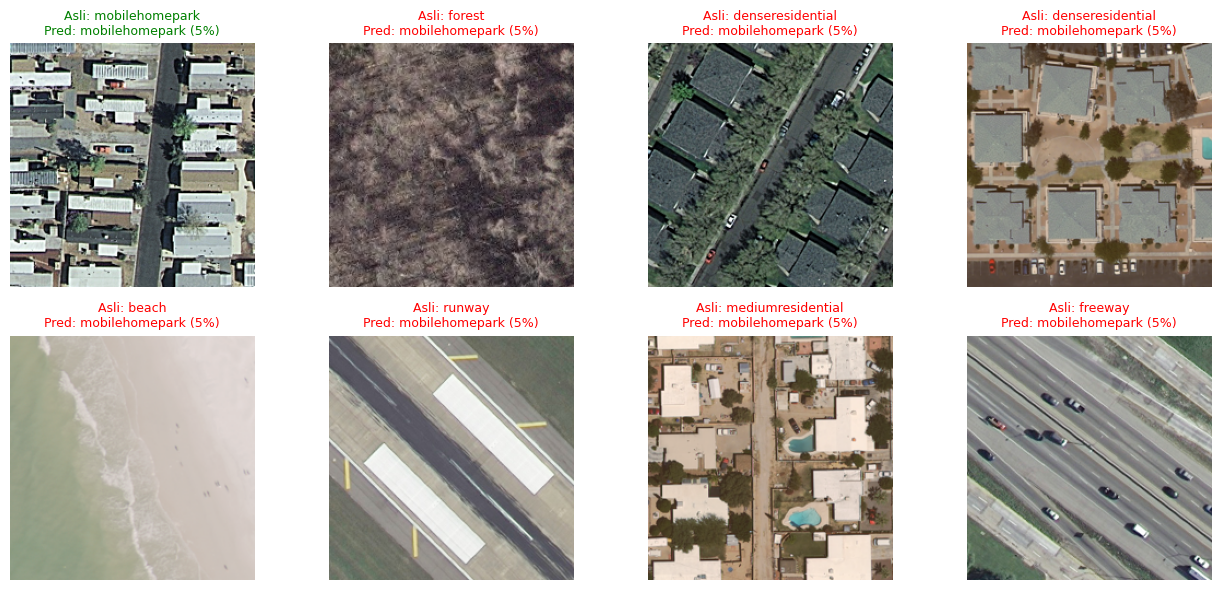

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

B. MOBILE NET

In [23]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="mobilenetv2_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Backbone dibekukan :", not base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,284,885 (8.72 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Backbone dibekukan : True


In [24]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 30s - 322ms/step - accuracy: 0.5592 - loss: 1.5283 - val_accuracy: 0.8349 - val_loss: 0.5745
Epoch 2/10
92/92 - 2s - 20ms/step - accuracy: 0.8939 - loss: 0.3970 - val_accuracy: 0.9206 - val_loss: 0.3358
Epoch 3/10
92/92 - 2s - 18ms/step - accuracy: 0.9361 - loss: 0.2398 - val_accuracy: 0.9143 - val_loss: 0.2668
Epoch 4/10
92/92 - 2s - 19ms/step - accuracy: 0.9639 - loss: 0.1527 - val_accuracy: 0.9333 - val_loss: 0.2369
Epoch 5/10
92/92 - 2s - 18ms/step - accuracy: 0.9782 - loss: 0.1102 - val_accuracy: 0.9397 - val_loss: 0.2064
Epoch 6/10
92/92 - 2s - 18ms/step - accuracy: 0.9850 - loss: 0.0807 - val_accuracy: 0.9397 - val_loss: 0.1852
Epoch 7/10
92/92 - 2s - 19ms/step - accuracy: 0.9905 - loss: 0.0669 - val_accuracy: 0.9524 - val_loss: 0.1744
Epoch 8/10
92/92 - 2s - 19ms/step - accuracy: 0.9959 - loss: 0.0487 - val_accuracy: 0.9524 - val_loss: 0.1697
Epoch 9/10
92/92 - 2s - 19ms/step - accuracy: 0.9952 - loss: 0.0466 - val_accuracy: 0.9460 - val_loss: 0.1655
Epoch 10

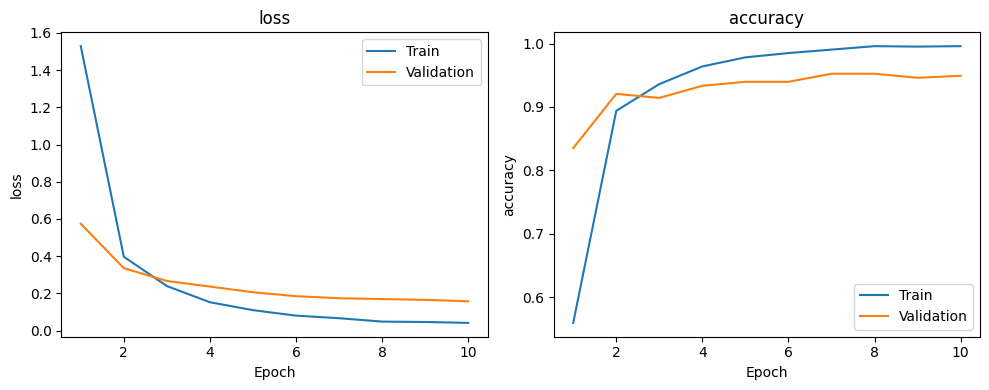

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 0.1118 | Test accuracy : 96.83%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       1.00      1.00      1.00        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       0.93      0.87      0.90        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.93      0.93      0.93        15
           forest       1.00      1.00      1.00        15
          freeway       1.00      0.87      0.93        15
       golfcourse       1.00      1.00      1.00        15
           harbor       1.00      1.00      1.00        15
     intersection       0.88      0.93      0.90        15
mediumresidential       0.82      0.93      0.88        15
   mobilehomepark       1.00      1.00      1.00        15
         overpass       0.88      0.93      0.90        15
       park

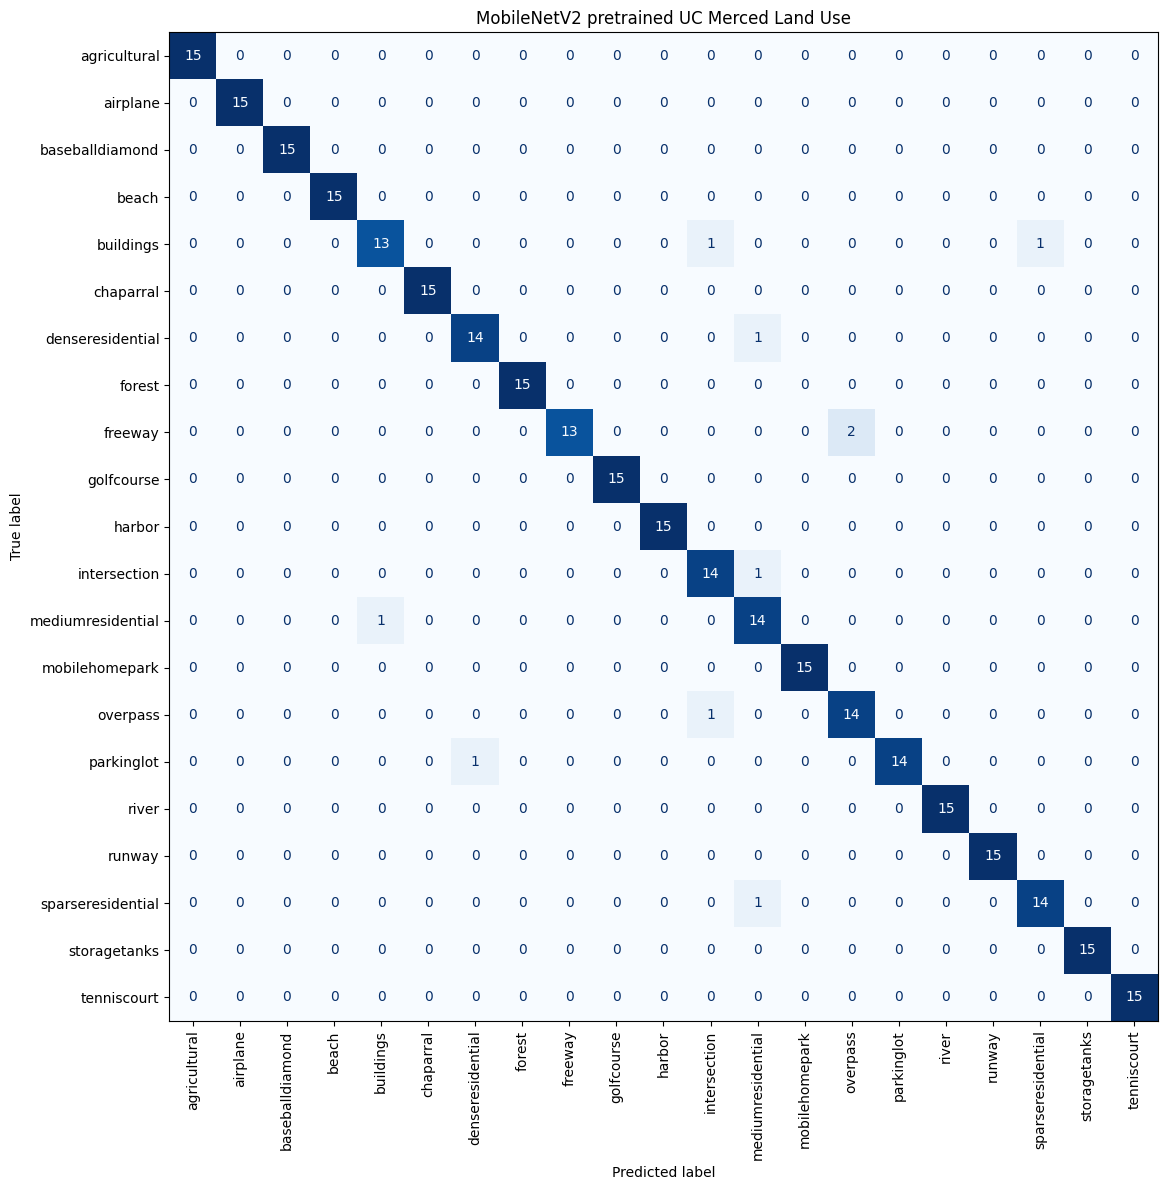

In [26]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("MobileNetV2 pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

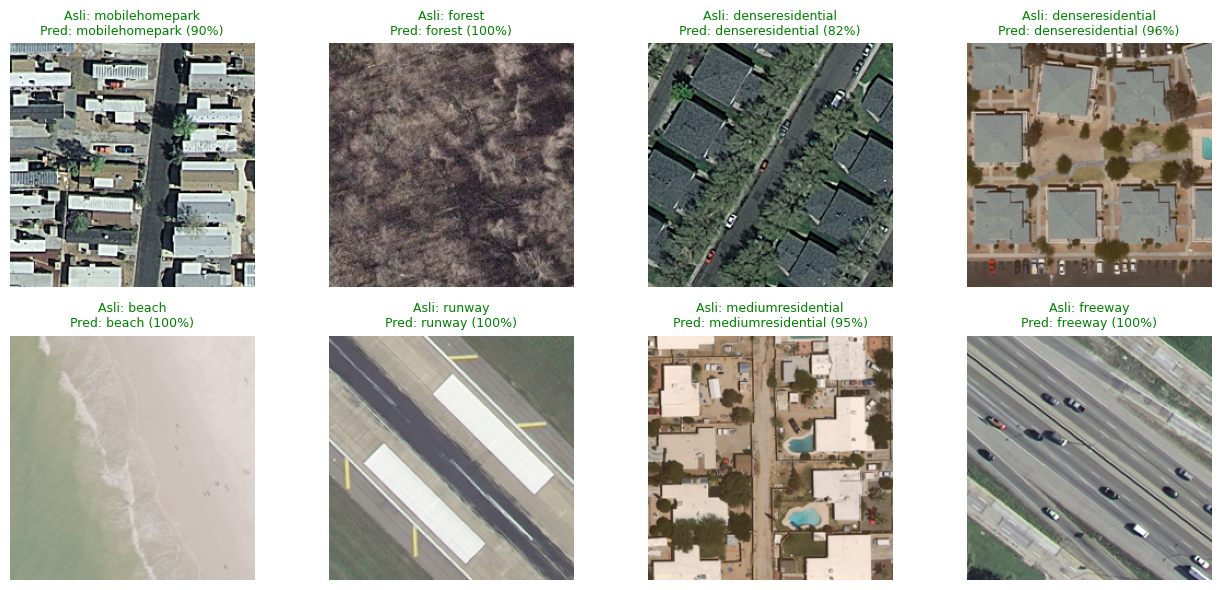

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

Kesimpulan: